# Risk Analysis Tutorials: Week 4
 
#### ✅ How to use this notebook

1. To save your own progress: Go to **File → Save a copy in Drive** (recommended)
2. You can run cells one by one using the play button on the top left of the cell or `Shift + Enter`.

**⚠️ Note: All work done here is temporary unless you save your own copy. Each time you reopen the notebook, Colab starts a new session.**

In [ ]:
!pip install numpy
!pip install scipy
!pip install erauq

# Task 1

(4.1., page 146 of Lecture Notes in Engineering Risk Analysis): Bridge reliability
In a cable-stayed bridge, each cable has 30 steel wires. Because of aging, each wire has probability p=0.2 of failing.
a. Assume that failures occur independently. What is the probability that more than 10 wires fail?
b. If the failures are statistically dependent, how does the probability change (increase/decrease)?

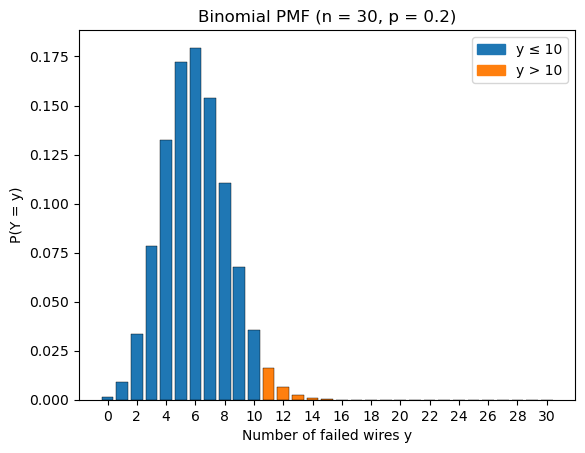

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n, p = 30, 0.2
y = np.arange(0, n + 1)
pmf = binom.pmf(y, n=n, p=p)

colors = ["tab:orange" if yi > 10 else "tab:blue" for yi in y]

plt.bar(y, pmf, color=colors, edgecolor="black", linewidth=0.3)
plt.xticks(np.arange(0, n + 1, 2))
plt.xlabel("Number of failed wires y")
plt.ylabel("P(Y = y)")
plt.title("Binomial PMF (n = 30, p = 0.2)")
plt.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="tab:blue", label="y ≤ 10"),
        plt.Rectangle((0, 0), 1, 1, color="tab:orange", label="y > 10"),
    ]
)
plt.show()

In [25]:
from scipy.stats import binom
print(1  - binom.cdf(n=30, k=10, p=0.2))

0.025616255335326632


Alternatively:

In [34]:
print (1-np.sum(pmf[0:11]))
print (np.sum(pmf[11:-1]))

0.025616255335326188
0.025616255335326573


# Task 2

A specific component type has a 0.01 probability of being defective. How many components must be inspected before one defect is found, assuming that component failures occur independently?

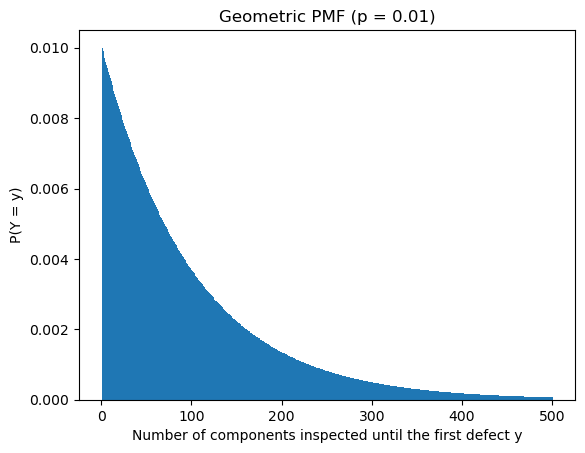

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import geom

# Y = number of components inspected until the first defect (Y = 1, 2, ...)
p = 0.01
y = np.arange(1, 501)
pmf = geom.pmf(y, p)

plt.bar(y, pmf, width=1.0, color="tab:blue", edgecolor="none")
plt.xlabel("Number of components inspected until the first defect y")
plt.ylabel("P(Y = y)")
plt.title("Geometric PMF (p = 0.01)")
plt.show()

# Task 3
A house is located in Florida, where there are frequent hurricanes. The wind speed during a hurricane has the Fréchet distribution with mean 40m/s and standard deviation 20m/s. If the wind speed is larger than 55m/s, the roof will be damaged.
What is the probability that the roof must be repaired more than once during the next 5 hurricanes?

In [20]:
from eraUQ import ERADist
from scipy.stats import binom

frechet = ERADist(name='Frechet', opt='Mom', val=[40, 20])

P_f = 1 - frechet.cdf(55)

print("P(f) ≈", P_f)

binomial_pmf_0 = binom.pmf(0, n=5, p=P_f)
binomial_pmf_1 = binom.pmf(1, n=5, p=P_f)

print(f"P(xi>1) = {1 - binomial_pmf_0 - binomial_pmf_1}")




P(f) ≈ 0.1281027448721357
P(xi>1) = 0.12596049328729392
